# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1:



**Student(s):** Sufyan Billel

**Date:** 11/16/2026

In [ ]:
# Your Phase 1 solution to the problem goes here.


### Q1.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, accuracy_score

try:
    from google.colab import drive
    drive.mount('/content/drive')
    path = '/content/drive/MyDrive/DS3001/heart_failure_clinical_records_dataset.csv'
except Exception as e:
    print(f"Could not mount Google Drive ({type(e).__name__}). Falling back to local file.")
    path = 'heart_failure_clinical_records_dataset.csv'

df = pd.read_csv(path)
print(df.shape)
df.head()

Could not mount Google Drive (MessageError). Falling back to local file.
(299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [6]:
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print(df.dtypes)
df.describe().T

Missing values: 0
Duplicate rows: 0
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object


,count,mean,std,min,25%,50%,75%,max
age,299.0,60.833893,11.894809,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.431438,0.496107,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.839465,970.287881,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.418060,0.494067,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.083612,11.834841,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.351171,0.478136,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.029264,97804.236869,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.393880,1.034510,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.625418,4.412477,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.648829,0.478136,0.0,0.0,1.0,1.0,1.0


In [7]:
print(df['DEATH_EVENT'].value_counts())
print('Share who died:', round(df['DEATH_EVENT'].mean(), 3))

DEATH_EVENT
0    203
1     96
Name: count, dtype: int64
Share who died: 0.321


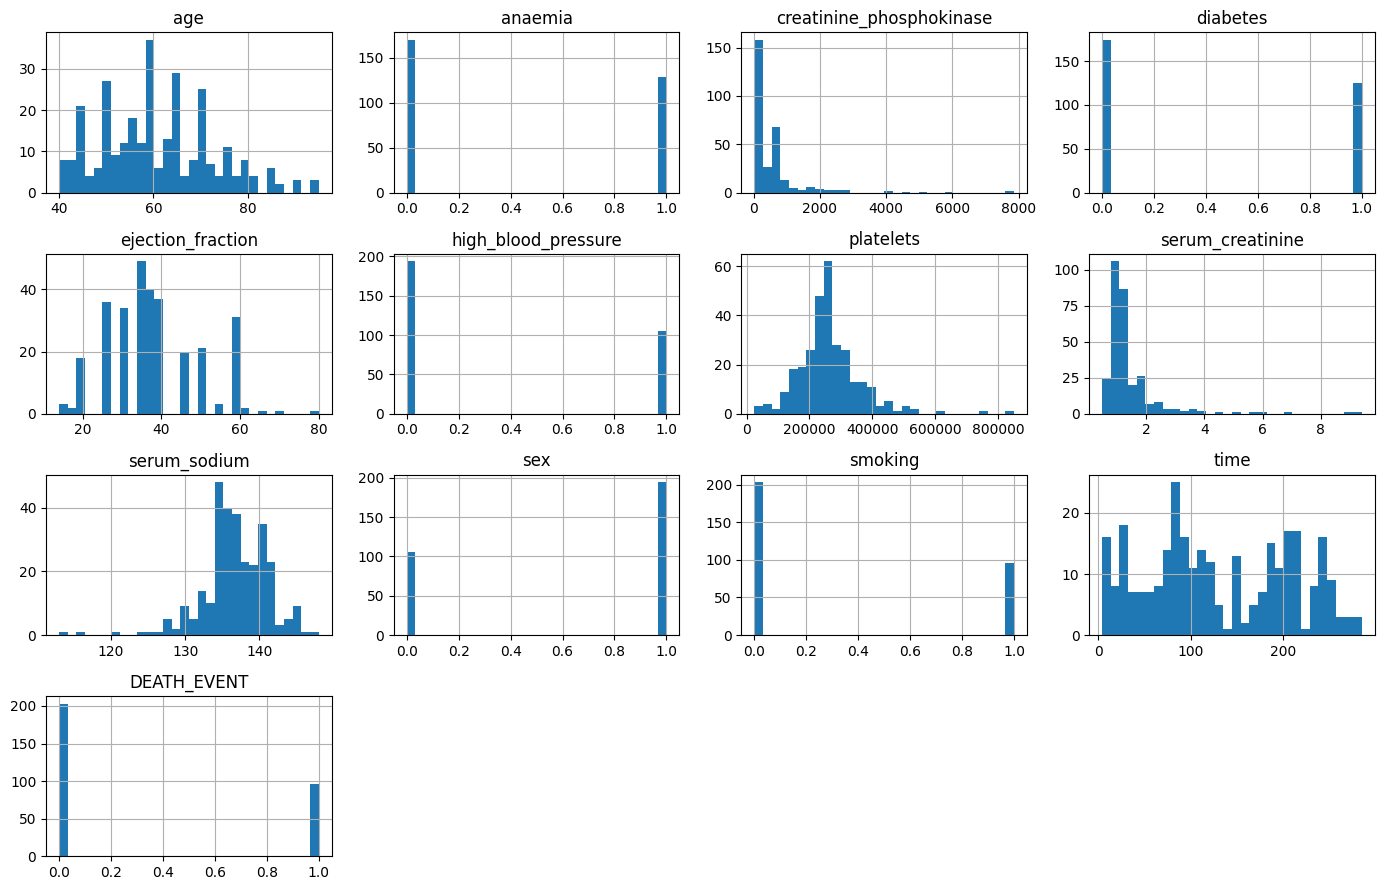

In [8]:
df.hist(figsize=(14, 9), bins=30)
plt.tight_layout()
plt.show()

In [11]:
# Values that show up often (likely filled-in values in the original data)
for c in ['platelets', 'creatinine_phosphokinase', 'age']:
    print(c, df[c].value_counts().head(3).to_dict())

platelets {263358.03: 25, 226000.0: 4, 255000.0: 4}
creatinine_phosphokinase {582: 47, 129: 4, 66: 4}
age {60.0: 33, 50.0: 27, 65.0: 26}


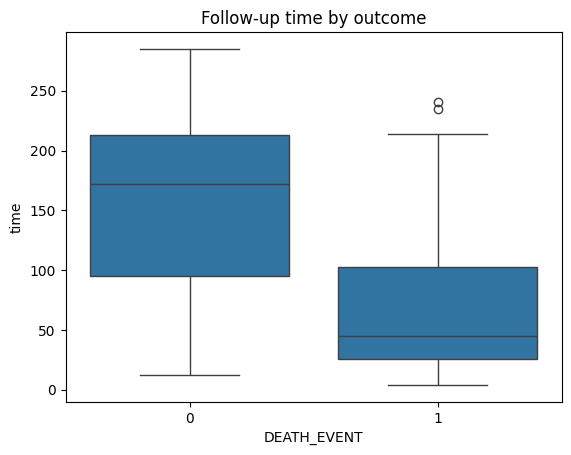

DEATH_EVENT
0    172.0
1     44.5
Name: time, dtype: float64


In [12]:
# Follow-up time vs death: patients who died were followed for a much shorter time
sns.boxplot(data=df, x='DEATH_EVENT', y='time')
plt.title('Follow-up time by outcome')
plt.show()
print(df.groupby('DEATH_EVENT')['time'].median())

In [13]:
print(df.corr()['DEATH_EVENT'].sort_values())

time                       -0.526964
ejection_fraction          -0.268603
serum_sodium               -0.195204
platelets                  -0.049139
smoking                    -0.012623
sex                        -0.004316
diabetes                   -0.001943
creatinine_phosphokinase    0.062728
anaemia                     0.066270
high_blood_pressure         0.079351
age                         0.253729
serum_creatinine            0.294278
DEATH_EVENT                 1.000000
Name: DEATH_EVENT, dtype: float64


**What the data look like.** There are 299 heart-failure patients and 13 columns, with no missing values and no duplicate rows. The outcome `DEATH_EVENT` is 1 if the patient died during follow-up, which happened for 32% of patients. Six columns are 0/1 indicators (anaemia, diabetes, high blood pressure, sex, smoking, and the outcome). The rest are numeric.

**Problems and cleaning decisions:**
- **`time` leaks the outcome, dropped it.** It is the length of the follow-up period, not something measured about the patient at the start. Patients who died were followed for a median of 44.5 days vs 172 days for survivors, because follow-up ends when the patient dies. It has by far the strongest correlation with death (-0.53), but a model can only "know" it after the outcome has happened.
- **Two lab values are very right-skewed.** `creatinine_phosphokinase` ranges from 23 to 7,861 and `serum_creatinine` from 0.5 to 9.4, so I take their logs. A few extreme patients would otherwise pull the linear model around. Trees only use the order of values, so the log doesn't change them.
- **Some values look filled in.** Platelets = 263,358.03 appears 25 times (it equals the column mean), creatinine phosphokinase = 582 appears 47 times, and some ages are 60.667. These look like values imputed by whoever built the data set. With only 299 patients I keep them rather than lose up to 72 rows, but I note them as a weakness of the data.
- The 0/1 variables are already in usable form, so no other encoding is needed.

In [14]:
# Cleaning
clean = df.drop(columns=['time']).copy()   # follow-up time leaks the outcome

# log transform the two very right-skewed lab values (helps the linear model; trees don't care)
clean['log_cpk'] = np.log(clean.pop('creatinine_phosphokinase'))
clean['log_creatinine'] = np.log(clean.pop('serum_creatinine'))

X = clean.drop(columns=['DEATH_EVENT'])
y = clean['DEATH_EVENT']
features = list(X.columns)
print(X.shape)
X.describe().T[['mean', 'min', 'max']]

(299, 11)


,mean,min,max
age,60.833893,40.000000,95.000000
anaemia,0.431438,0.000000,1.000000
diabetes,0.418060,0.000000,1.000000
ejection_fraction,38.083612,14.000000,80.000000
high_blood_pressure,0.351171,0.000000,1.000000
platelets,263358.029264,25100.000000,850000.000000
serum_sodium,136.625418,113.000000,148.000000
sex,0.648829,0.000000,1.000000
smoking,0.321070,0.000000,1.000000
log_cpk,5.659896,3.135494,8.969669


### Q2.

In [15]:
MAIN_SEED = 3001

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=MAIN_SEED, stratify=y)
print(len(X_train), 'train,', len(X_test), 'test')
print('Death rate train:', round(y_train.mean(), 3), ' test:', round(y_test.mean(), 3))

239 train, 60 test
Death rate train: 0.322  test: 0.317


In [16]:
# Pick the tree's depth and minimum leaf size by 5-fold cross-validation on the training set.
# These settings are then kept FIXED for every seed, so differences between trees come
# only from the data, not from re-tuning.
grid = GridSearchCV(DecisionTreeClassifier(random_state=0),
                    {'max_depth': [1, 2, 3, 4, 5, 6], 'min_samples_leaf': [1, 5, 10, 20]},
                    cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring='roc_auc')
grid.fit(X_train, y_train)
tree_params = grid.best_params_
print('Chosen tree settings:', tree_params, ' CV AUC:', round(grid.best_score_, 3))

Chosen tree settings: {'max_depth': 6, 'min_samples_leaf': 10}  CV AUC: 0.768


In [17]:
def fit_models(seed):
    # Split with the given seed, fit a tree and a linear model, and return them.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    tree = DecisionTreeClassifier(**tree_params, random_state=0).fit(Xtr, ytr)
    # Linear probability model: linear regression of the 0/1 outcome on the features.
    # Features are standardized so the coefficients are comparable across variables.
    linear = make_pipeline(StandardScaler(), LinearRegression()).fit(Xtr, ytr)
    return {'seed': seed, 'tree': tree, 'linear': linear, 'X_test': Xte, 'y_test': yte}

def evaluate(m):
    # Performance of a seed's models on its OWN test set
    p_tree = m['tree'].predict_proba(m['X_test'])[:, 1]
    p_lin = m['linear'].predict(m['X_test'])
    out = {}
    for name, p in [('tree', p_tree), ('linear', p_lin)]:
        out[name + '_accuracy'] = accuracy_score(m['y_test'], p >= 0.5)
        out[name + '_AUC'] = roc_auc_score(m['y_test'], p)
        out[name + '_RMSE'] = np.sqrt(np.mean((m['y_test'] - p) ** 2))
    return out

main = fit_models(MAIN_SEED)
pd.Series(evaluate(main)).round(3)

,0
tree_accuracy,0.800
tree_AUC,0.728
tree_RMSE,0.430
linear_accuracy,0.750
linear_AUC,0.710
linear_RMSE,0.446


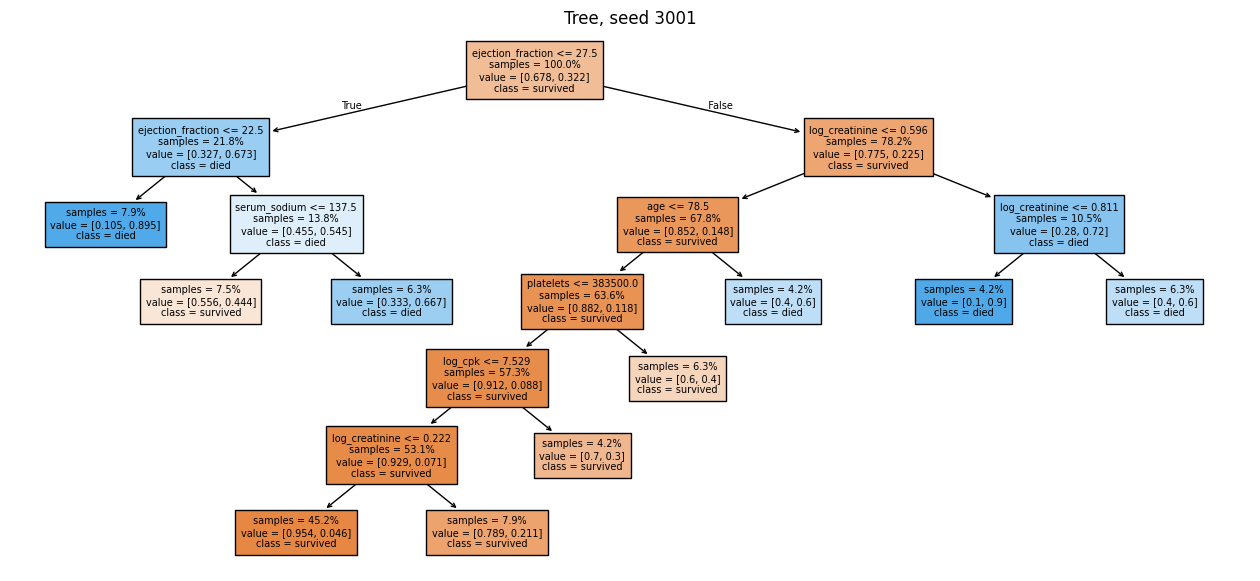

In [18]:
# Set aside the predicted probability of death on the Q2 test set
pred_tree_main = main['tree'].predict_proba(X_test)[:, 1]
pred_lin_main = main['linear'].predict(X_test)

plt.figure(figsize=(16, 7))
plot_tree(main['tree'], feature_names=features, class_names=['survived', 'died'],
          filled=True, impurity=False, proportion=True, fontsize=7)
plt.title(f'Tree, seed {MAIN_SEED}')
plt.show()

In [19]:
pd.Series(main['linear'][-1].coef_, index=features).round(3).sort_values()

,0
ejection_fraction,-0.144
sex,-0.049
serum_sodium,-0.031
diabetes,-0.031
platelets,0.006
high_blood_pressure,0.011
smoking,0.015
anaemia,0.029
log_cpk,0.036
age,0.083


**Seed 3001.** The split is stratified so the death rate is about 32% in both the training and test sets. I treat death as a probability to predict:
- **Tree:** a classification tree. Cross-validation on the training set picked depth 6 with at least 10 patients per leaf. Its prediction is the share of deaths in a patient's leaf.
- **Linear model:** a linear regression of the 0/1 outcome on standardized features (a linear probability model). Each coefficient is the change in predicted death probability for a one standard deviation increase in that feature.

**Test-set performance.** The tree gets 80% accuracy (AUC 0.73) and the linear model 75% (AUC 0.71). For comparison, always predicting "survived" would be about 68% accurate. With only 60 test patients these numbers are noisy: one patient is 1.7 percentage points of accuracy.
 Both models agree on what matters:
- **Tree:** the first split is ejection fraction ≤ 27.5% (how well the heart pumps). The next splits use ejection fraction again and creatinine (kidney function).
- **Linear model:** the largest coefficients are ejection fraction (-0.14) and log creatinine (+0.12), followed by age (+0.08). Sex, diabetes, smoking and platelets are close to zero.

### Q3

In [20]:
ALT_SEEDS = [11, 22, 33, 44, 55]
alts = [fit_models(s) for s in ALT_SEEDS]

perf = pd.DataFrame([evaluate(m) for m in [main] + alts], index=[MAIN_SEED] + ALT_SEEDS)
perf.index.name = 'seed'
perf.round(3)

,tree_accuracy,tree_AUC,tree_RMSE,linear_accuracy,linear_AUC,linear_RMSE
seed,,,,,,
3001,0.800,0.728,0.430,0.750,0.710,0.446
11,0.767,0.743,0.440,0.800,0.825,0.406
22,0.700,0.747,0.442,0.783,0.820,0.397
33,0.833,0.918,0.356,0.800,0.887,0.373
44,0.733,0.757,0.444,0.733,0.822,0.411
55,0.833,0.784,0.389,0.783,0.841,0.390


In [21]:
# Set aside each alternative model's predictions on the SAME Q2 test set, so they can be compared
alt_tree_preds = {m['seed']: m['tree'].predict_proba(X_test)[:, 1] for m in alts}
alt_lin_preds = {m['seed']: m['linear'].predict(X_test) for m in alts}

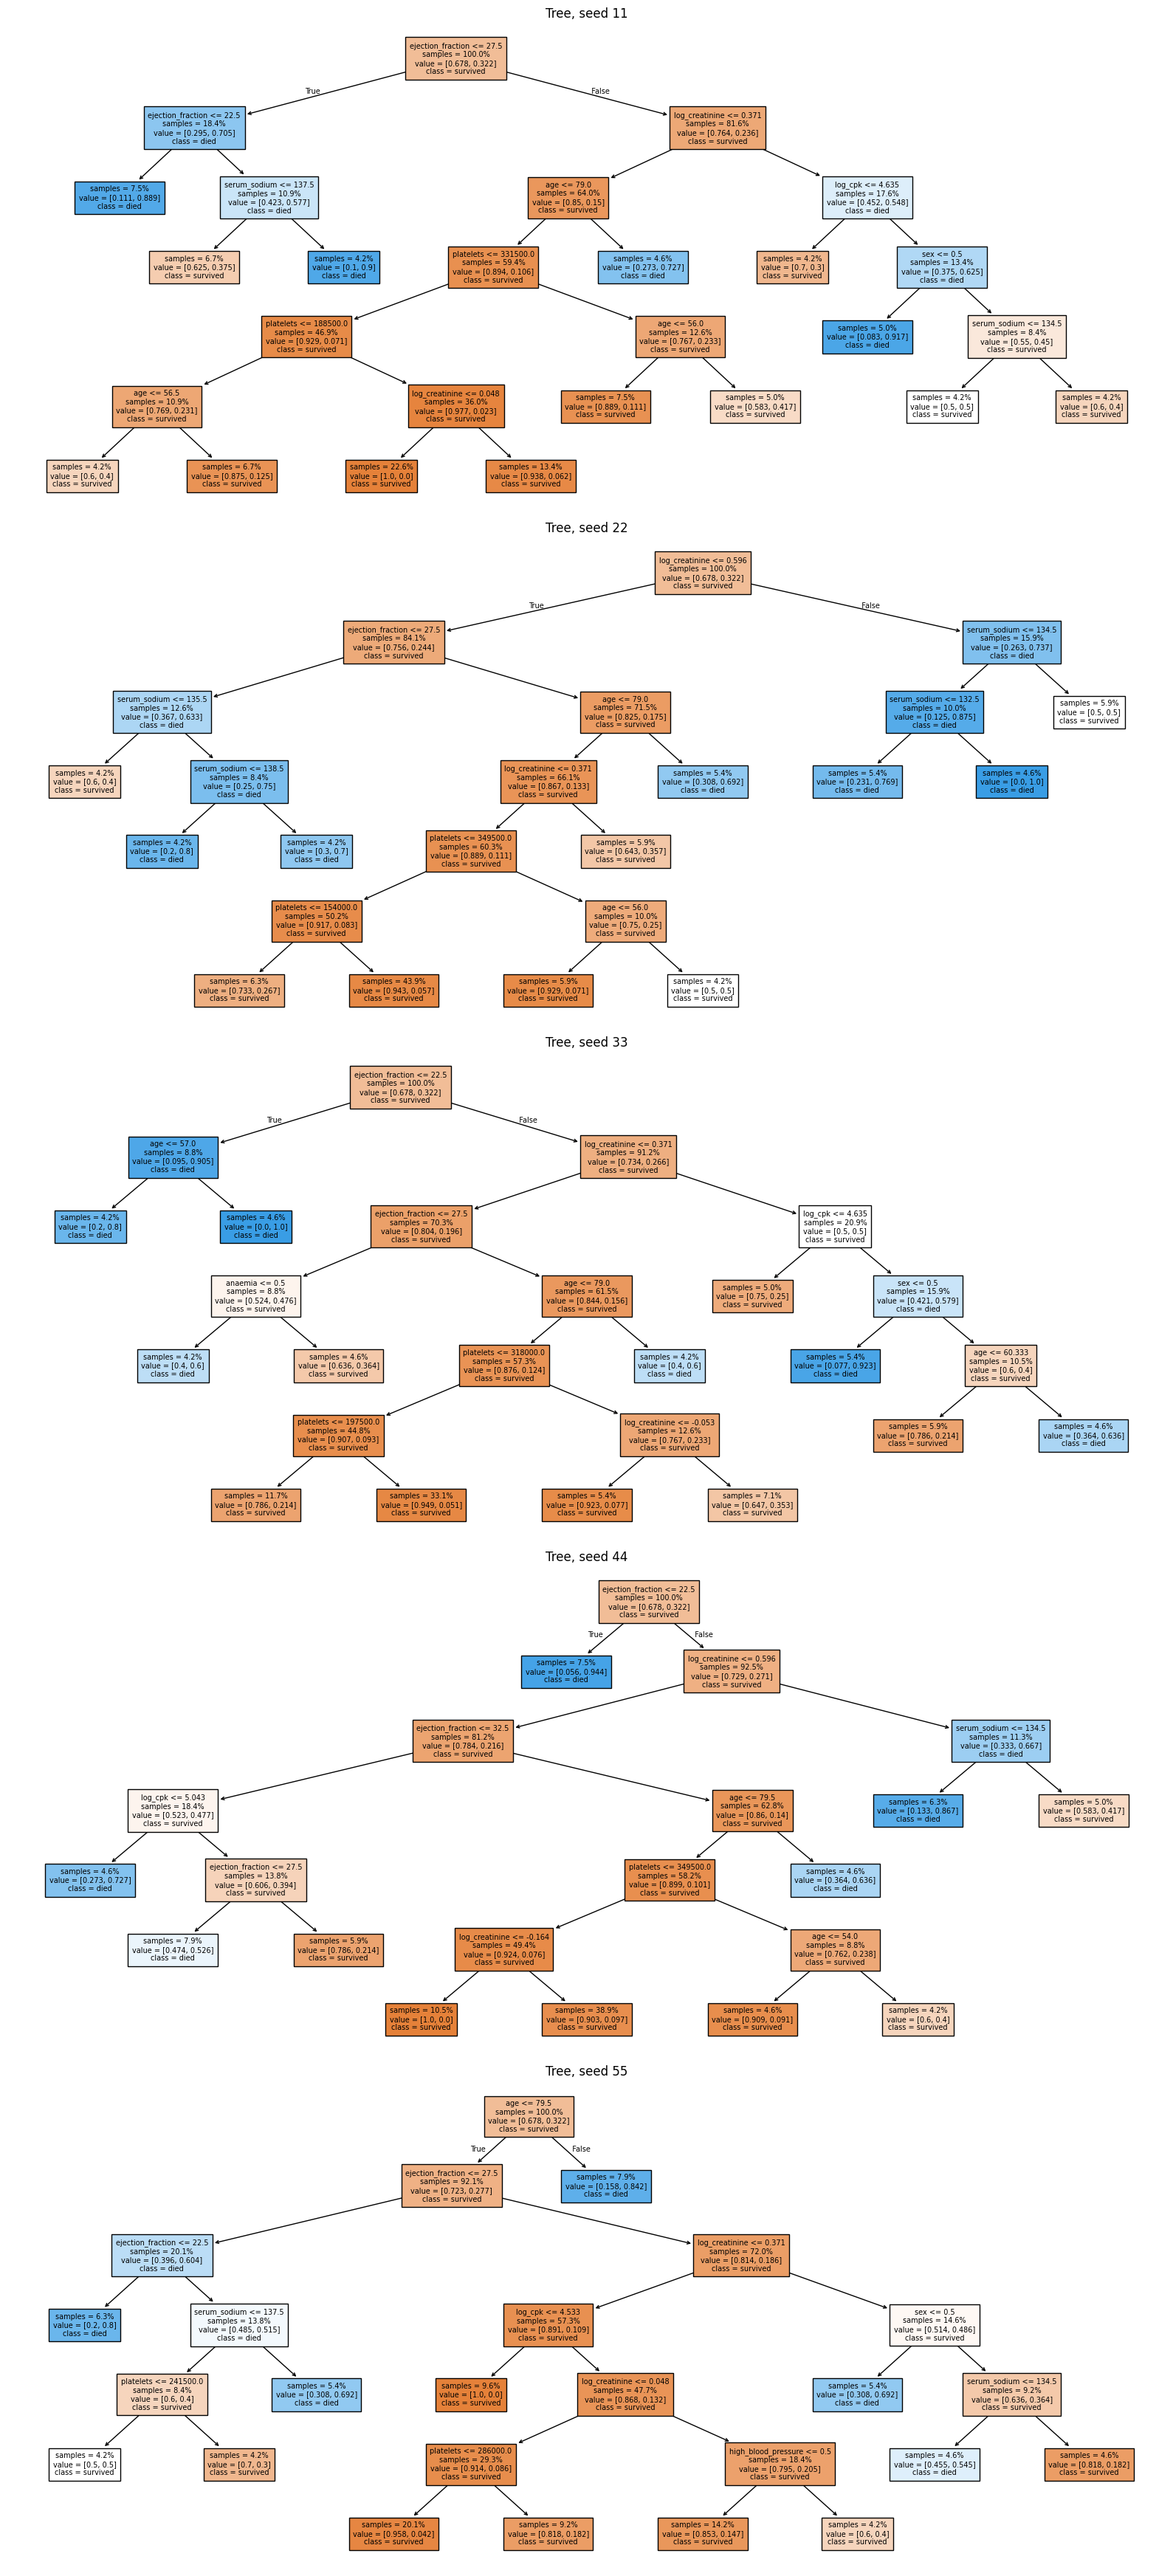

In [22]:
fig, axes = plt.subplots(len(alts), 1, figsize=(16, 7 * len(alts)))
for m, ax in zip(alts, axes):
    plot_tree(m['tree'], feature_names=features, class_names=['survived', 'died'],
              filled=True, impurity=False, proportion=True, fontsize=7, ax=ax)
    ax.set_title(f"Tree, seed {m['seed']}")
plt.tight_layout()
plt.show()

In [23]:
# Summarize how the trees differ
def root_split(tree):
    t = tree.tree_
    return f"{features[t.feature[0]]} <= {t.threshold[0]:.2f}"

def second_splits(tree):
    t = tree.tree_
    kids = [t.children_left[0], t.children_right[0]]
    return ', '.join(features[t.feature[k]] if t.feature[k] >= 0 else 'leaf' for k in kids)

tree_summary = pd.DataFrame([{
    'seed': m['seed'],
    'root split': root_split(m['tree']),
    'level-2 splits': second_splits(m['tree']),
    'leaves': m['tree'].get_n_leaves(),
    'variables used': int((m['tree'].feature_importances_ > 0).sum()),
} for m in [main] + alts]).set_index('seed')
tree_summary

,root split,level-2 splits,leaves,variables used
seed,,,,
3001,ejection_fraction <= 27.50,"ejection_fraction, log_creatinine",10,6
11,ejection_fraction <= 27.50,"ejection_fraction, log_creatinine",14,7
22,log_creatinine <= 0.60,"ejection_fraction, serum_sodium",12,5
33,ejection_fraction <= 22.50,"age, log_creatinine",13,7
44,ejection_fraction <= 22.50,"leaf, log_creatinine",11,6
55,age <= 79.50,"ejection_fraction, leaf",13,8


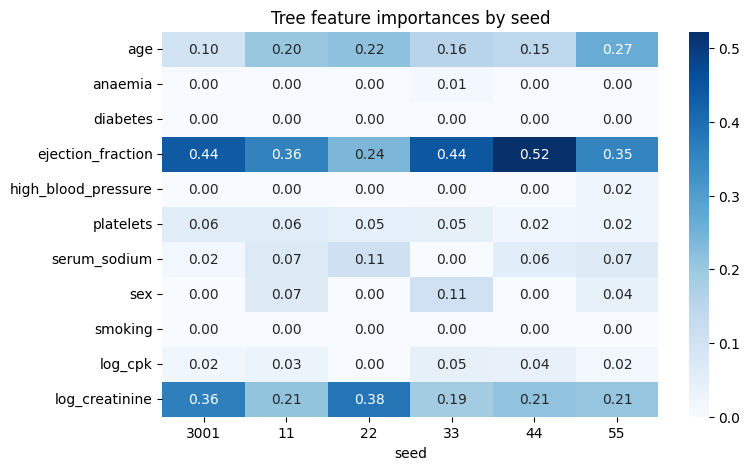

In [24]:
importances = pd.DataFrame({m['seed']: m['tree'].feature_importances_ for m in [main] + alts},
                           index=features)
plt.figure(figsize=(8, 5))
sns.heatmap(importances, annot=True, fmt='.2f', cmap='Blues')
plt.xlabel('seed')
plt.title('Tree feature importances by seed')
plt.show()

In [25]:
coefs = pd.DataFrame({m['seed']: m['linear'][-1].coef_ for m in [main] + alts}, index=features)
coefs['mean'] = coefs.mean(axis=1)
coefs['std'] = coefs.iloc[:, :6].std(axis=1)
coefs['sign changes?'] = (np.sign(coefs.iloc[:, :6]).nunique(axis=1) > 1)
coefs.round(3).sort_values('mean')

,3001,11,22,33,44,55,mean,std,sign changes?
ejection_fraction,-0.144,-0.124,-0.102,-0.106,-0.107,-0.099,-0.114,0.017,False
serum_sodium,-0.031,-0.037,-0.049,-0.052,-0.043,-0.044,-0.043,0.008,False
sex,-0.049,-0.003,-0.042,-0.003,-0.011,-0.021,-0.021,0.020,False
diabetes,-0.031,-0.008,0.006,-0.006,0.007,0.001,-0.005,0.014,True
platelets,0.006,-0.012,0.001,0.004,-0.011,-0.003,-0.003,0.008,True
smoking,0.015,0.000,0.010,0.001,0.018,0.026,0.012,0.010,False
anaemia,0.029,0.026,0.025,0.042,0.049,0.025,0.033,0.010,False
high_blood_pressure,0.011,0.032,0.022,0.042,0.057,0.038,0.034,0.016,False
log_cpk,0.036,0.044,0.027,0.048,0.048,0.030,0.039,0.009,False
age,0.083,0.077,0.096,0.068,0.071,0.112,0.085,0.017,False


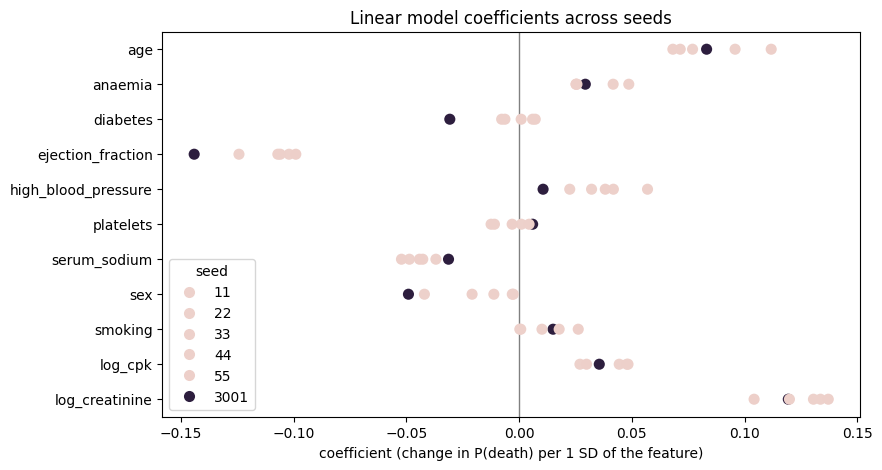

In [26]:
coef_long = coefs.iloc[:, :6].reset_index().melt(id_vars='index', var_name='seed', value_name='coef')
plt.figure(figsize=(9, 5))
sns.stripplot(data=coef_long, y='index', x='coef', hue='seed', size=8, jitter=False)
plt.axvline(0, color='grey', lw=1)
plt.ylabel('')
plt.xlabel('coefficient (change in P(death) per 1 SD of the feature)')
plt.title('Linear model coefficients across seeds')
plt.show()

Test performance moves around a lot  from seed to seed: tree AUC ranges from 0.73 to 0.92 and linear AUC from 0.71 to 0.89. That is mostly because each seed has a different small test set, not because the models are very different.

The trees look different:
- Root split: four of the six trees start with ejection fraction, but at two different cutoffs (27.5 and 22.5). Seed 22 starts with creatinine and seed 55 with age ≤ 79.5.
- Second level: the splits differ in almost every tree.
- Size:the trees have 10 to 14 leaves and use 5 to 8 different variables.
- Importances: ejection fraction, creatinine and age are always the most important, but their shares move a lot. Creatinine ranges from 0.19 to 0.38 and ejection fraction from 0.24 to 0.52. Sex and serum sodium matter in some trees and not at all in others.

If you read each tree as "the" story of who dies, you would tell six different stories.

**The linear coefficients barely move.** Every coefficient's standard deviation across seeds is 0.02 or less. The ordering is the same every time: log creatinine, ejection fraction and age are the biggest effects, and serum sodium, CPK, blood pressure and anaemia come next with the same signs. The only coefficients that change sign are diabetes and platelets, and both are essentially zero in every seed (|coefficient| ≤ 0.03).

### Q4. Are the predictions actually different?

All models below are compared on the **same rows**: the Q2 test set (60 patients). One caveat: the alternative splits are different, so some of these 60 patients were in an alternative model's *training* data. That can only make the alternative predictions look more similar to each other than they would on completely new patients.

In [ ]:
# How many Q2 test patients each alternative model trained on
for m in alts:
    in_train = (~X_test.index.isin(m['X_test'].index)).sum()
    print(f"seed {m['seed']}: {in_train} of {len(X_test)} Q2 test patients were in its training set")

seed 11: 52 of 60 Q2 test patients were in its training set
seed 22: 51 of 60 Q2 test patients were in its training set
seed 33: 46 of 60 Q2 test patients were in its training set
seed 44: 48 of 60 Q2 test patients were in its training set
seed 55: 47 of 60 Q2 test patients were in its training set


**4a. Scatterplots**

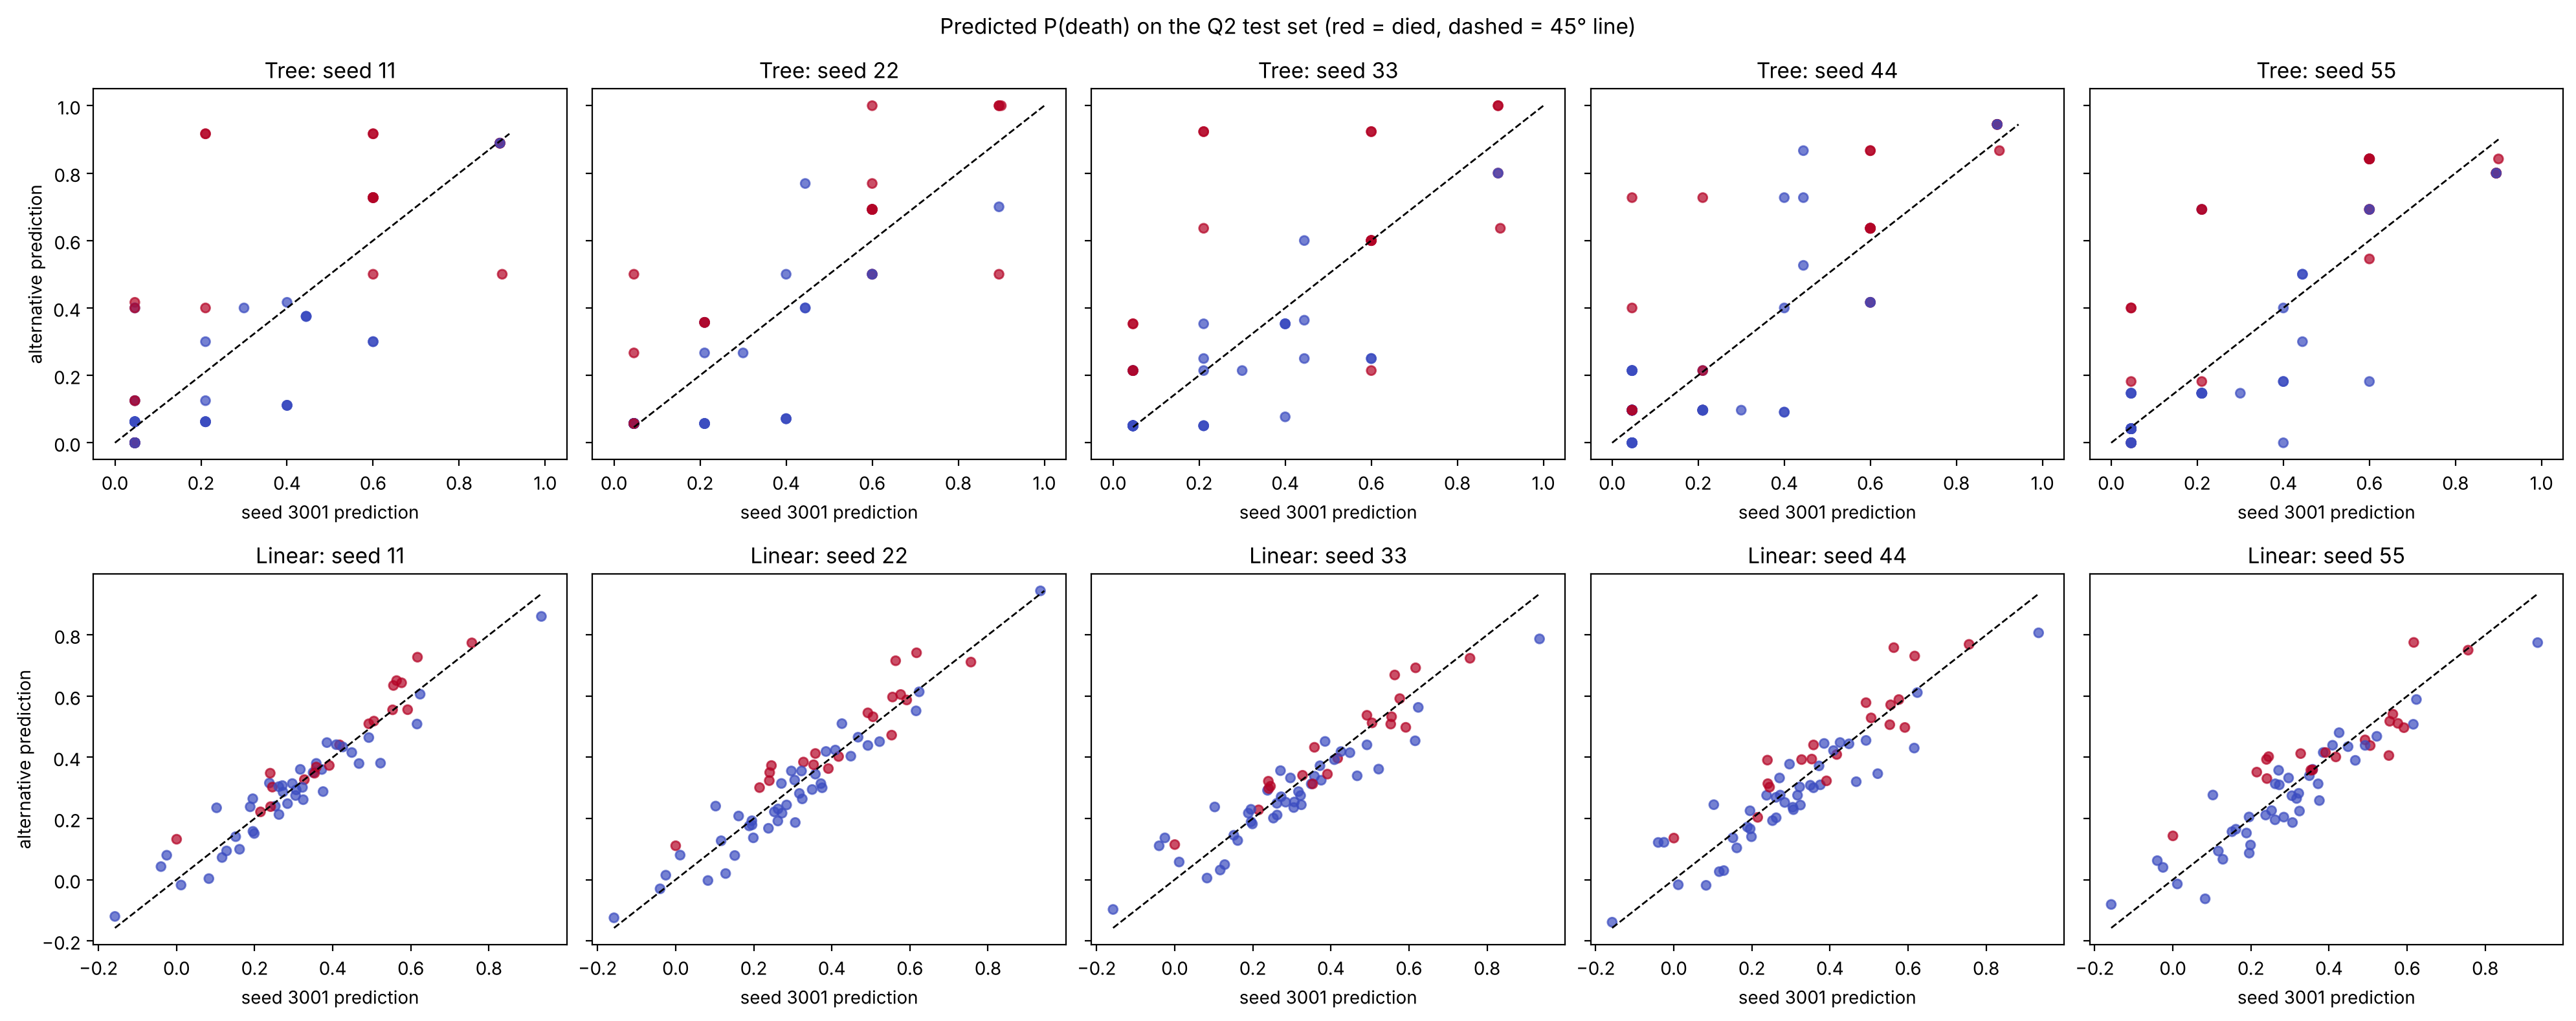

In [ ]:
fig, axes = plt.subplots(2, len(alts), figsize=(4 * len(alts), 8), sharex='row', sharey='row')
for j, s in enumerate(ALT_SEEDS):
    for i, (name, main_pred, alt_pred) in enumerate([('Tree', pred_tree_main, alt_tree_preds[s]),
                                                     ('Linear', pred_lin_main, alt_lin_preds[s])]):
        ax = axes[i, j]
        ax.scatter(main_pred, alt_pred, c=y_test, cmap='coolwarm', s=25, alpha=0.7)
        lo = min(main_pred.min(), alt_pred.min()); hi = max(main_pred.max(), alt_pred.max())
        ax.plot([lo, hi], [lo, hi], 'k--', lw=1)
        ax.set_title(f'{name}: seed {s}')
        ax.set_xlabel(f'seed {MAIN_SEED} prediction')
        if j == 0:
            ax.set_ylabel('alternative prediction')
plt.suptitle('Predicted P(death) on the Q2 test set (red = died, dashed = 45° line)')
plt.tight_layout()
plt.show()

**Linear models:** the points sit tightly around the 45° line for every seed. A patient the seed-3001 model calls high risk is high risk for every alternative model too.

**Trees:** the points follow the 45° line in general (low-risk patients stay low, high-risk patients stay high), but the scatter is much wider. Each tree can only predict one of its 10–14 leaf values, so the points stack into columns. Several patients get about 0.05 from one tree and 0.4–0.9 from another. So the tree predictions are similar in direction, but not reasonably close for individual patients.

**4b. Correlations**

In [ ]:
corr_table = pd.DataFrame({
    'tree': [np.corrcoef(pred_tree_main, alt_tree_preds[s])[0, 1] for s in ALT_SEEDS],
    'linear': [np.corrcoef(pred_lin_main, alt_lin_preds[s])[0, 1] for s in ALT_SEEDS],
}, index=pd.Index(ALT_SEEDS, name='alternative seed'))
corr_table.loc['average'] = corr_table.mean()
corr_table.round(3)

,tree,linear
alternative seed,,
11,0.781,0.956
22,0.869,0.949
33,0.756,0.935
44,0.832,0.915
55,0.830,0.914
average,0.814,0.934


**Linear models are highly correlated:** 0.91 to 0.96, average 0.93.

**Trees are positively but less correlated:** 0.76 to 0.87, average 0.81. Given how different the trees look, that is more agreement than I expected. It still leaves noticeably more disagreement than the linear models.

**4c. Simple linear regressions: alternative prediction on the Q2 prediction**

In [ ]:
rows = []
for s in ALT_SEEDS:
    for name, main_pred, alt_pred in [('tree', pred_tree_main, alt_tree_preds[s]),
                                      ('linear', pred_lin_main, alt_lin_preds[s])]:
        reg = LinearRegression().fit(main_pred.reshape(-1, 1), alt_pred)
        rows.append({'model': name, 'seed': s, 'intercept': reg.intercept_, 'slope': reg.coef_[0],
                     'R2': reg.score(main_pred.reshape(-1, 1), alt_pred)})
slr = pd.DataFrame(rows)
display(slr.pivot(index='seed', columns='model', values=['intercept', 'slope', 'R2']).round(3))
slr.groupby('model')[['intercept', 'slope', 'R2']].mean().round(3)

intercept         slope            R2       
model    linear   tree linear   tree linear   tree
seed                                              
11        0.028  0.041  0.932  0.904  0.914  0.609
22        0.012  0.027  0.974  0.950  0.901  0.756
33        0.049  0.080  0.832  0.819  0.875  0.572
44        0.031  0.062  0.898  0.941  0.836  0.692
55        0.043  0.043  0.845  0.931  0.836  0.689

,intercept,slope,R2
model,,,
linear,0.033,0.896,0.872
tree,0.051,0.909,0.664


| | Intercept (want 0) | Slope (want 1) | $R^2$ (want 1) |
|---|---|---|---|
| Linear (average) | 0.03 | 0.90 | 0.87 |
| Tree (average) | 0.05 | 0.91 | 0.66 |

- **Intercepts** are close to zero for both, so neither set of models predicts systematically higher or lower.
- **Slopes** are close to 1 for both on average. The linear slopes range from 0.83 to 0.97 and the tree slopes from 0.82 to 0.95.
- **$R^2$ is where they differ.** The linear models are fairly close to 1 (0.84–0.91). The trees are not (0.57–0.76): about a third of the variation in a tree's predictions isn't explained by what the seed-3001 tree predicted.

**Robustness check.** Because most Q2 test patients were in the alternative models' training data, I repeat 4b and 4c with alternative models that never see the Q2 test set: each one is trained on a bootstrap resample (drawn with replacement) of the Q2 *training* set, using the same seeds.

In [ ]:
rows = []
for s in ALT_SEEDS:
    boot = X_train.sample(frac=1, replace=True, random_state=s).index
    tree_b = DecisionTreeClassifier(**tree_params, random_state=0).fit(X_train.loc[boot], y_train.loc[boot])
    lin_b = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train.loc[boot], y_train.loc[boot])
    for name, main_pred, alt_pred in [('tree', pred_tree_main, tree_b.predict_proba(X_test)[:, 1]),
                                      ('linear', pred_lin_main, lin_b.predict(X_test))]:
        reg = LinearRegression().fit(main_pred.reshape(-1, 1), alt_pred)
        rows.append({'model': name, 'seed': s, 'correlation': np.corrcoef(main_pred, alt_pred)[0, 1],
                     'intercept': reg.intercept_, 'slope': reg.coef_[0],
                     'R2': reg.score(main_pred.reshape(-1, 1), alt_pred)})
boot_table = pd.DataFrame(rows)
display(boot_table.pivot(index='seed', columns='model', values='correlation').round(3))
boot_table.groupby('model')[['correlation', 'intercept', 'slope', 'R2']].mean().round(3)

model,linear,tree
seed,,
11,0.816,0.635
22,0.958,0.661
33,0.965,0.452
44,0.906,0.567
55,0.891,0.693


,correlation,intercept,slope,R2
model,,,,
linear,0.907,-0.027,1.095,0.826
tree,0.602,0.085,0.687,0.369


**This check matters.** In the comparisons above, 46–52 of the 60 test patients were in each alternative model's training data. When every model has to predict truly new patients:
- **Linear models** barely change: correlation 0.91, slope 1.10, $R^2$ 0.83.
- **Trees** agree much less: correlation 0.60, slope 0.69, $R^2$ 0.37.

So part of the trees' agreement in 4a–4c came from trees memorizing patients they had already seen. On new patients, two trees trained on slightly different data agree only moderately.

### Q5. Stability of coefficients and predictions

**Linear models: yes, on both counts.** The coefficients have the same signs, the same ordering and almost the same sizes across splits (standard deviations of 0.02 or less). Their predictions on the same patients correlate above 0.9, with intercept near 0, slope near 1 and $R^2$ above 0.8, including on patients no model trained on.

**Trees: no for the structure, and only partly for the predictions.** The root split, the cutoffs, the depth of each branch and the variables used all change from seed to seed. Their predictions do agree in direction: all trees use ejection fraction, creatinine and age, so high-risk patients tend to stay high risk. But that agreement is moderate. Correlation is 0.81 on the shared test set and 0.60 on fully new patients, and individual patients can move from a 5% predicted risk to 40–90%.

### Q6. True or false?

**Mostly false for this dataset, and how false depends on the model.**

- **Linear models:** the statement is true, but the premise doesn't apply. Their appearance (the coefficients) doesn't change much, and neither do their predictions.
- **Trees:** this is where the statement is really tested, and it only half holds. The trees do look very different, yet their predictions are more similar than the pictures suggest. They always lean on the same few variables, so on the shared test set the correlation is 0.81 with intercept near 0 and slope near 1. That is the true part: a different-looking tree is not a completely different model.
- **"Very similar" is too strong.** $R^2$ between tree predictions is only 0.66 on the shared test set. On patients none of the trees trained on, it drops to 0.37 (correlation 0.60). Individual patients' predicted risk changes a lot between trees, which would matter if the predictions were used to decide who gets extra care.

**Why it fails here.** With only 299 patients, each tree is built on around 240 people and each leaf on as few as 10. Shifting a handful of patients can move a split, and every split below it changes. The linear model averages over all patients, so it is far more stable. The usual fix for tree instability is to average many trees (bagging or a random forest), which keeps the trees' flexibility while removing much of this split-to-split noise.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.
